In [8]:
import time
import matplotlib.pyplot as plt
from matplotlib import style
style.use("dark_background")
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader,random_split,Subset
import torchvision
from torchvision import datasets,transforms
from torchsummary import summary
device = 'cuda' if  torch.cuda.is_available else 'cpu'
device

'cuda'

In [9]:
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder("train",transform=transform_train)
test_data = datasets.ImageFolder("test",transform=transform_test)

In [20]:
len(test_data.classes)

7

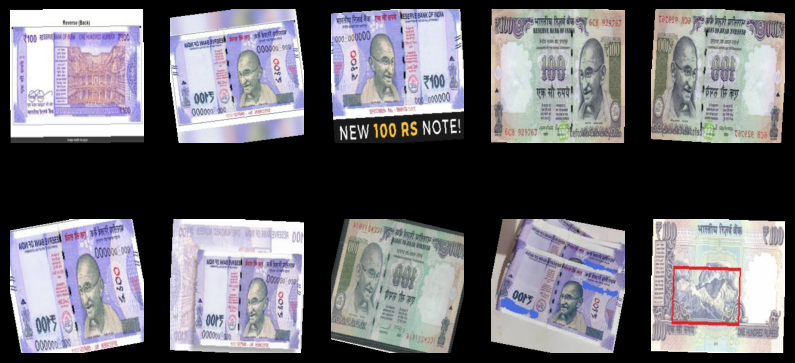

In [10]:
fig,axes = plt.subplots(2,5,figsize=(10,5))
for i,ax in enumerate(axes.flat):
    image,label = train_data[i]
    ax.imshow(image.permute(1,2,0))
    ax.axis('off')
plt.show()

In [11]:
train_loader = DataLoader(train_data, batch_size= 64, shuffle = True, drop_last = True,num_workers = 4,pin_memory=True,persistent_workers = True)
test_loader = DataLoader(test_data, batch_size = 64,num_workers=4,pin_memory=True,persistent_workers = True)

In [17]:
resnet = torchvision.models.resnet18('ResNet18_Weights.DEFAULT')
resnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [18]:
summary(resnet.cuda(),(3,256,256))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]           9,408
       BatchNorm2d-2         [-1, 64, 128, 128]             128
              ReLU-3         [-1, 64, 128, 128]               0
         MaxPool2d-4           [-1, 64, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          36,864
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
            Conv2d-8           [-1, 64, 64, 64]          36,864
       BatchNorm2d-9           [-1, 64, 64, 64]             128
             ReLU-10           [-1, 64, 64, 64]               0
       BasicBlock-11           [-1, 64, 64, 64]               0
           Conv2d-12           [-1, 64, 64, 64]          36,864
      BatchNorm2d-13           [-1, 64, 64, 64]             128
             ReLU-14           [-1, 64,

In [19]:
for p in resnet.parameters():
    p.requires_grad = False

for p in resnet.layer4.parameters():
    p.requires_grad = True

for p in resnet.fc.parameters():
    p.requires_grad = True

In [21]:
resnet.fc = nn.Linear(512,7)
resnet.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [22]:
epochs = 10
lossfunc = nn.CrossEntropyLoss()
losses = torch.zeros(epochs)
trainAcc = []
testAcc = []
optimizer = torch.optim.Adam(resnet.parameters(), lr=1e-4)
scaler = GradScaler()
for epoch in range(epochs):
    batchAcc = []
    batchLoss = []
    train_acc = []
    start_time = time.time()
    for X,y in train_loader:
        resnet.train()
        X = X.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        with autocast():
            ypred = resnet(X)
            loss = lossfunc(ypred, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        batchLoss.append(loss.item())
        acc = 100*(torch.argmax(ypred,dim = 1) == y).float().mean().item()
        train_acc.append(acc)
    end_time = time.time()
    epoch_time = end_time - start_time
    losses[epoch] = np.mean(batchLoss)
    trainAcc.append(np.mean(train_acc))
    all_pred = []
    all_label = []
    with torch.no_grad():
        resnet.eval()
        acc_test = []
        for X,y in test_loader:
            X = X.to(device)
            y = y.to(device)
            ypred = resnet(X)
            preds = torch.argmax(ypred, dim=1)
            all_pred.extend(preds.cpu().numpy())
            all_label.extend(y.cpu().numpy())

            acc = 100*(torch.argmax(ypred,dim = 1) == y).float().mean().item()
            acc_test.append(acc)
        testAcc.append(np.mean(acc_test))

    if epoch % 5 == 0:
        print(f'epoch: {epoch}, loss: {losses[epoch]},time: {epoch_time}')

torch.save(resnet.state_dict(), 'resnet.pth')

C:\Users\amsha\AppData\Local\Temp\ipykernel_8604\2577335005.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
C:\Users\amsha\AppData\Local\Temp\ipykernel_8604\2577335005.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


epoch: 0, loss: 2.108570098876953,time: 5.2153284549713135
epoch: 5, loss: 0.5365562438964844,time: 0.5314986705780029


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(losses, 'white', lw=3, label='training loss')
ax[0].set_title('loss')
ax[0].legend()
ax[1].plot(testAcc, 'white', lw=3, label='test accuracy')
ax[1].plot(trainAcc, 'gray', lw=3, label='training accuracy')
ax[1].set_title(f'train Acc {trainAcc[-1]} test Acc {testAcc[-1]}')
ax[1].legend()
plt.show()